In [16]:
"""
SAM index from CMIP6 sea-level pressure (psl) files.

Definition: Gong & Wang (1999) zonal-mean version
    SAM(t) = P*(40S, t) - P*(65S, t)
where P* is the zonal-mean MSLP at that latitude, normalised per calendar
month by the mean and standard deviation of a fixed reference period.

Historical and SSP3-7.0 files are concatenated into one continuous series so
the reference-period normalisation is identical for both, which keeps the
projected SAM trend interpretable.

Outputs per model:
    sam_<model>_monthly.csv   monthly index + experiment label
    sam_<model>_annual.csv    annual and seasonal means
    sam_<model>.nc            monthly index as NetCDF
"""

from pathlib import Path
import re

import numpy as np
import pandas as pd
import xarray as xr

# ----------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------
DATA_DIR = Path("D:/PolarRESHackthon/DataNew/psl")
OUT_DIR = DATA_DIR

MODELS = ["CESM2", "MPI-ESM1-2-LR"]
EXPERIMENTS = ["historical", "ssp370"]

# Reference period for the normalisation. 1979-2014 is covered by both models
# (MPI historical starts 1970, CESM2 in 1950) and matches the satellite era.
REF_START, REF_END = 1985, 2014

LAT_NORTH = -40.0
LAT_SOUTH = -65.0

# Normalise the final index by its own reference-period std as well.
# False = original Gong & Wang. True = unit-variance index, easier to compare
# across models.
STANDARDISE_INDEX = True


# ----------------------------------------------------------------------
# Helpers
# ----------------------------------------------------------------------
def find_files(model, experiment):
    """All psl files for one model/experiment, sorted by start date."""
    pattern = "psl_Amon_{}_{}_*.nc".format(model, experiment)
    files = list(DATA_DIR.glob(pattern))
    if not files:
        raise FileNotFoundError("No files matching {} in {}".format(pattern, DATA_DIR))

    def start_date(p):
        m = re.search(r"_(\d{6})-(\d{6})\.nc$", p.name)
        return int(m.group(1)) if m else 0

    return sorted(files, key=start_date)


def standardise_coords(ds):
    """Rename lat/lon variants to 'lat'/'lon'."""
    rename = {}
    for cand, target in [("latitude", "lat"), ("longitude", "lon")]:
        if cand in ds.coords or cand in ds.dims:
            rename[cand] = target
    return ds.rename(rename) if rename else ds


def load_psl(model):
    """Concatenate historical + ssp370 psl into one time series."""
    files = []
    for exp in EXPERIMENTS:
        files += find_files(model, exp)

    ds = xr.open_mfdataset(
        files,
        combine="by_coords",
        use_cftime=True,          # CESM2 is noleap, MPI proleptic_gregorian
        chunks={"time": 120},
        coords="minimal",
        data_vars="minimal",
        compat="override",
    )
    ds = standardise_coords(ds)

    psl = ds["psl"]
    # Drop duplicate timestamps in case historical/ssp overlap
    _, idx = np.unique(psl["time"], return_index=True)
    psl = psl.isel(time=np.sort(idx))
    return psl.sortby("time")


def zonal_mean_at(psl, lat0):
    """Zonal-mean MSLP interpolated to a single latitude."""
    zm = psl.mean("lon", keep_attrs=True)
    if float(zm["lat"][0]) > float(zm["lat"][-1]):   # ensure increasing lat
        zm = zm.sortby("lat")
    return zm.interp(lat=lat0).drop_vars("lat", errors="ignore")


def normalise_monthly(series, ref_slice):
    """(x - monthly mean) / monthly std over the reference period."""
    ref = series.sel(time=ref_slice)
    clim = ref.groupby("time.month").mean("time")
    std = ref.groupby("time.month").std("time")
    anom = series.groupby("time.month") - clim
    return anom.groupby("time.month") / std


def experiment_label(years):
    return np.where(np.asarray(years) <= 2014, "historical", "ssp370")


# ----------------------------------------------------------------------
# Main computation
# ----------------------------------------------------------------------
def sam_for_model(model):
    print("\n=== {} ===".format(model))
    psl = load_psl(model)
    print("  grid: {} x {}, {} months ({} to {})".format(
        psl.sizes["lat"], psl.sizes["lon"], psl.sizes["time"],
        psl.time.values[0], psl.time.values[-1]))

    ref = slice("{}-01".format(REF_START), "{}-12".format(REF_END))

    p40 = zonal_mean_at(psl, LAT_NORTH).compute()
    p65 = zonal_mean_at(psl, LAT_SOUTH).compute()

    sam = normalise_monthly(p40, ref) - normalise_monthly(p65, ref)

    if STANDARDISE_INDEX:
        sam = sam / sam.sel(time=ref).std("time")

    sam = sam.rename("sam").drop_vars("month", errors="ignore")
    sam.attrs = {
        "long_name": "Southern Annular Mode index",
        "definition": "Gong and Wang (1999): normalised zonal-mean MSLP at "
                      "40S minus 65S",
        "reference_period": "{}-{}".format(REF_START, REF_END),
        "standardised": str(STANDARDISE_INDEX),
        "model": model,
    }

    # ---- tidy monthly table ----
    years = np.array([t.year for t in sam.time.values])
    months = np.array([t.month for t in sam.time.values])
    df = pd.DataFrame({
        "year": years,
        "month": months,
        "experiment": experiment_label(years),
        "model": model,
        "sam": sam.values,
    })

    # ---- annual and seasonal means (DJF labelled by its Jan/Feb year) ----
    season_map = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
                  6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
    df["season"] = pd.Series(months).map(season_map).values
    df["season_year"] = np.where(months == 12, years + 1, years)

    annual = df.groupby(["model", "year"])["sam"].mean().rename("annual")
    seasonal = (df.groupby(["model", "season_year", "season"])["sam"]
                  .mean().unstack("season"))
    seasonal.index.names = ["model", "year"]
    summary = seasonal.join(annual).reset_index()
    summary["experiment"] = experiment_label(summary["year"].values)

    # ---- write ----
    tag = model.replace("/", "-")
    df.to_csv(OUT_DIR / "sam_{}_monthly.csv".format(tag), index=False)
    summary.to_csv(OUT_DIR / "sam_{}_annual.csv".format(tag), index=False)
    sam.to_netcdf(OUT_DIR / "sam_{}.nc".format(tag))
    print("  written: sam_{}_monthly.csv / _annual.csv / .nc".format(tag))

    return sam, df


if __name__ == "__main__":
    results = {}
    for model in MODELS:
        results[model] = sam_for_model(model)

    # Sanity check: DJF trend over the projection period
    for model, (sam, df) in results.items():
        djf = df[df["season"] == "DJF"].groupby("season_year")["sam"].mean()
        fut = djf.loc[2015:2100]
        slope = np.polyfit(fut.index.values, fut.values, 1)[0] * 10
        print("{}: DJF SAM trend 2015-2100 = {:+.3f} per decade".format(
            model, slope))


=== CESM2 ===


C:\Users\damiantf\AppData\Local\Programs\Python\Python313\Lib\site-packages\xarray\conventions.py:204: SerializationWarning: variable 'psl' has multiple fill values {np.float32(1e+20), np.float64(1e+20)} defined, decoding all values to NaN.
  var = coder.decode(var, name=name)
C:\Users\damiantf\AppData\Local\Temp\ipykernel_30480\3139222822.py:80: FutureWarning: Usage of 'use_cftime' as a kwarg is deprecated. Please pass a 'CFDatetimeCoder' instance initialized with 'use_cftime' to the 'decode_times' kwarg instead.
Example usage:
    time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)
    ds = xr.open_dataset(decode_times=time_coder)

  ds = xr.open_mfdataset(
C:\Users\damiantf\AppData\Local\Programs\Python\Python313\Lib\site-packages\xarray\conventions.py:204: SerializationWarning: variable 'psl' has multiple fill values {np.float32(1e+20), np.float64(1e+20)} defined, decoding all values to NaN.
  var = coder.decode(var, name=name)
C:\Users\damiantf\AppData\Local\Temp\ipykernel_304

  grid: 192 x 288, 1812 months (1950-01-15 12:00:00 to 2100-12-15 12:00:00)
  written: sam_CESM2_monthly.csv / _annual.csv / .nc

=== MPI-ESM1-2-LR ===


C:\Users\damiantf\AppData\Local\Temp\ipykernel_30480\3139222822.py:80: FutureWarning: Usage of 'use_cftime' as a kwarg is deprecated. Please pass a 'CFDatetimeCoder' instance initialized with 'use_cftime' to the 'decode_times' kwarg instead.
Example usage:
    time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)
    ds = xr.open_dataset(decode_times=time_coder)

  ds = xr.open_mfdataset(
C:\Users\damiantf\AppData\Local\Temp\ipykernel_30480\3139222822.py:80: FutureWarning: Usage of 'use_cftime' as a kwarg is deprecated. Please pass a 'CFDatetimeCoder' instance initialized with 'use_cftime' to the 'decode_times' kwarg instead.
Example usage:
    time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)
    ds = xr.open_dataset(decode_times=time_coder)

  ds = xr.open_mfdataset(
C:\Users\damiantf\AppData\Local\Temp\ipykernel_30480\3139222822.py:80: FutureWarning: Usage of 'use_cftime' as a kwarg is deprecated. Please pass a 'CFDatetimeCoder' instance initialized with 'use_cftime' to the 

  grid: 96 x 192, 1572 months (1970-01-16 12:00:00 to 2100-12-16 12:00:00)
  written: sam_MPI-ESM1-2-LR_monthly.csv / _annual.csv / .nc
CESM2: DJF SAM trend 2015-2100 = +0.048 per decade
MPI-ESM1-2-LR: DJF SAM trend 2015-2100 = +0.074 per decade


Marshall index rescaled by 1/1.715 (std over 1985–2014)

SAM trends (standardised units decade^-1, Theil-Sen; Mann-Kendall with Hamed-Rao correction)
  MPI-ESM1-2-LR  1985–2099  MK=increasing   p=0.0000  tau=+0.185  Sen=+0.0961 [+0.0786, +0.1140]
  MPI-ESM1-2-LR  2015–2099  MK=increasing   p=0.0000  tau=+0.142  Sen=+0.1006 [+0.0723, +0.1300]
  CESM2          1985–2099  MK=increasing   p=0.0000  tau=+0.198  Sen=+0.0895 [+0.0738, +0.1053]
  CESM2          2015–2099  MK=increasing   p=0.0000  tau=+0.159  Sen=+0.0956 [+0.0710, +0.1202]
  obs            1985–2025  MK=increasing   p=0.0051  tau=+0.095  Sen=+0.1238 [+0.0458, +0.2002]


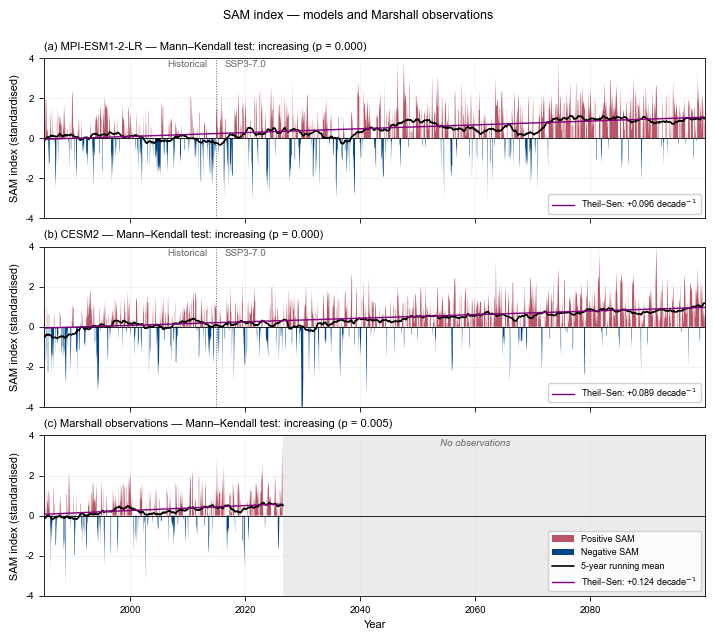

In [26]:
"""
SAM index figure formatted to Copernicus / Weather and Climate Dynamics (WCD)
figure guidelines.

Reads the per-model monthly CSVs written by compute_sam_index.py
(sam_CESM2_monthly.csv, sam_MPI-ESM1-2-LR_monthly.csv) and plots two
Theil-Sen trends per model panel: one over the full analysed period and one
over the SSP3-7.0 projection period only.

Guideline compliance notes
--------------------------
* Panel labels as lower-case letters in brackets: (a), (b), (c).
* Ranges use en dashes without spaces: 1985-2014, 2015-2099.
* Space between number and unit; units set exponentially: decade^-1.
* Headers capitalise the first word only (plus proper nouns).
* One sans-serif font family throughout, regular weight only, fonts embedded.
* Colour-vision-deficiency-safe palette (Paul Tol high-contrast); trends are
  additionally distinguishable by line style, not colour alone.
* All symbols explained in an in-figure legend, not in the caption text.
* Vector output (*.pdf, fonts embedded) plus a 300 dpi *.png fallback.
* Figure width 18 cm (well above the 8 cm minimum). Rename the file stem to
  f01 (etc.) at submission.
"""

import re
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from scipy.stats import theilslopes
from pymannkendall import hamed_rao_modification_test as mk_test

# -- Config ----------------------------------------------------------------
DATA_DIR = Path("D:/PolarRESHackthon/DataNew/psl")
OUT_STEM = "D:/PolarRESHackthon/Paper/SAM_trend"

SAM_FILES = {
    "CESM2": DATA_DIR / "sam_CESM2_monthly.csv",
    "MPI-ESM1-2-LR": DATA_DIR / "sam_MPI-ESM1-2-LR_monthly.csv",
}
models = ["MPI-ESM1-2-LR", "CESM2"]     # panel order (a), (b)

FULL_RANGE = ("1985", "2099")           # full analysed period, models
PROJ_RANGE = ("2015", "2099")           # SSP3-7.0 period only
OBS_TREND_RANGE = ("1985", "2025")      # observational period

MARSHALL_URL = "https://legacy.bas.ac.uk/met/gjma/newsam.1957.2007.txt"

# compute_sam_index.py was run with STANDARDISE_INDEX = True, so the model
# index has unit variance over its reference period while the Marshall index
# does not. Rescaling the observations over the same window puts all three
# panels on a common amplitude. Set to False (together with
# STANDARDISE_INDEX = False upstream) for the raw Gong and Wang comparison.
RESCALE_OBS = True
OBS_REF_RANGE = ("1985", "2014")

CM = 1 / 2.54                      # cm -> inch helper
FIG_W, FIG_H = 18 * CM, 16 * CM    # 18 cm wide (double column)

# -- Matplotlib style: one sans-serif family, regular weight, embedded fonts -
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8,
    "axes.titlesize": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6.5,
    "figure.titlesize": 9,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "pdf.fonttype": 42,            # embed TrueType, keep text selectable
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "axes.unicode_minus": False,
})

# CVD-safe palette (Paul Tol high-contrast): blue / red / yellow + black
C_POS = "#BB5566"        # positive SAM
C_NEG = "#004488"        # negative SAM
C_TREND_FULL = "purple"  # Theil-Sen, full period
C_TREND_PROJ = "purple"   # Theil-Sen, projection only
C_MEAN = "black"          # running mean


# -- Load model data -------------------------------------------------------
def load_model_sam(path):
    """Monthly SAM series from compute_sam_index.py output."""
    d = pd.read_csv(path)
    idx = pd.to_datetime(dict(year=d["year"], month=d["month"], day=1))
    s = pd.Series(d["sam"].to_numpy(), index=idx).sort_index()
    if s.index.has_duplicates:
        s = s[~s.index.duplicated(keep="first")]
    return s


dfs = {}
for m in models:
    s = load_model_sam(SAM_FILES[m])
    dfs[m] = s.loc[FULL_RANGE[0]:FULL_RANGE[1]]


# -- Load Marshall SAM observations ----------------------------------------
def load_marshall_sam(url=MARSHALL_URL):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    txt = urllib.request.urlopen(req, timeout=30).read().decode("utf-8", "replace")

    rows = {}
    for line in txt.splitlines():
        t = line.split()
        if not t or not re.fullmatch(r"\d{4}", t[0]):
            continue
        vals = []
        for tok in t[1:13]:
            try:
                vals.append(float(tok))
            except ValueError:
                vals.append(np.nan)
        rows[int(t[0])] = vals

    grid = pd.DataFrame.from_dict(
        rows, orient="index", columns=range(1, 13)
    ).sort_index()
    stacked = grid.stack(future_stack=True)
    idx = pd.to_datetime([f"{y:04d}-{m:02d}-01" for y, m in stacked.index])
    obs = pd.Series(stacked.to_numpy(), index=idx).replace([-99.99, -99.9], np.nan)
    return obs.sort_index()


obs = load_marshall_sam()

if RESCALE_OBS:
    obs_std = obs.loc[OBS_REF_RANGE[0]:OBS_REF_RANGE[1]].std()
    obs = obs / obs_std
    print(f"Marshall index rescaled by 1/{obs_std:.3f} "
          f"(std over {OBS_REF_RANGE[0]}\u2013{OBS_REF_RANGE[1]})")


# -- Trend helpers ---------------------------------------------------------
def decimal_year(index):
    return index.year + (index.dayofyear - 1) / 365.25


def trend_stats(series, label):
    """Mann-Kendall (Hamed-Rao) plus Theil-Sen slope on a decimal-year axis."""
    s = series.dropna()
    if len(s) < 24:
        return None
    t = decimal_year(s.index)
    mk = mk_test(s.values)
    slope, intercept, lo, hi = theilslopes(s.values, t)
    return {
        "label": label,
        "trend": mk.trend, "p": mk.p, "tau": mk.Tau,
        "slope_dec": slope * 10, "lo_dec": lo * 10, "hi_dec": hi * 10,
        "intercept": intercept, "t": t, "index": s.index,
        "start": s.index.min(), "end": s.index.max(),
    }


def period_label(rng):
    return f"{rng[0]}\u2013{rng[1]}"


# two trends per model, one for the observations
trends = {}
for m in models:
    trends[m] = {
        "full": trend_stats(dfs[m].loc[FULL_RANGE[0]:FULL_RANGE[1]],
                            period_label(FULL_RANGE)),
        "proj": trend_stats(dfs[m].loc[PROJ_RANGE[0]:PROJ_RANGE[1]],
                            period_label(PROJ_RANGE)),
    }
trends["obs"] = {
    "full": trend_stats(obs.loc[OBS_TREND_RANGE[0]:OBS_TREND_RANGE[1]],
                        period_label(OBS_TREND_RANGE)),
    "proj": None,
}

print("\nSAM trends (standardised units decade^-1, Theil-Sen; "
      "Mann-Kendall with Hamed-Rao correction)")
for key, d in trends.items():
    for st in d.values():
        if st is None:
            continue
        print(f"  {key:<14} {st['label']:<10} "
              f"MK={st['trend']:<12} p={st['p']:.4f}  tau={st['tau']:+.3f}  "
              f"Sen={st['slope_dec']:+.4f} "
              f"[{st['lo_dec']:+.4f}, {st['hi_dec']:+.4f}]")


# -- Figure ----------------------------------------------------------------
fig, axes = plt.subplots(3, 1, figsize=(FIG_W, FIG_H), sharex=True)

fig.suptitle("SAM index \u2014 models and Marshall observations", y=0.995)

panels = [(m, dfs[m], m, trends[m]) for m in models]
panels += [("obs", obs, "Marshall observations", trends["obs"])]

panel_letters = ["(a)", "(b)", "(c)"]

for i, (ax, letter, (key, s, label, tr)) in enumerate(
        zip(axes, panel_letters, panels)):

    # SAM anomaly bars
    ax.fill_between(s.index, s, 0, where=s >= 0, color=C_POS,
                    linewidth=0, label="Positive SAM")
    ax.fill_between(s.index, s, 0, where=s < 0, color=C_NEG,
                    linewidth=0, label="Negative SAM")

    ax.axhline(0, color="black", linewidth=0.6)

    # 5-year running mean (60 monthly steps)
    rolling = s.rolling(window=60, center=True, min_periods=30).mean()
    ax.plot(rolling.index, rolling, color=C_MEAN, linewidth=1.2,
            solid_capstyle="round", label="5-year running mean", zorder=5)

    # Theil-Sen trends, each drawn only over the period it was fitted to
    st = tr["full"]
    if st is not None:
        line = st["intercept"] + (st["slope_dec"] / 10) * st["t"]
        ax.plot(st["index"], line, color=C_TREND_FULL, linestyle="-",
                linewidth=1, solid_capstyle="round", zorder=6,
                label=(f"Theil\u2013Sen: "
                       f"{st['slope_dec']:+.3f} decade$^{{-1}}$ "))


    ax.set_ylim(-4, 4)
    ax.set_yticks(np.arange(-4, 5, 2))
    ax.set_ylabel("SAM index (standardised)")

    # Header: panel letter in brackets, first word capitalised only.
    # Trend statistics live in the legend, since each panel now carries two.
        # Header: panel letter in brackets, first word capitalised only
    if st is not None:
        ax.set_title(
            f"{letter} {label} — Mann–Kendall test: {st['trend']} "
            f"(p = {st['p']:.3f})",
            loc="left",
        )
    else:
        ax.set_title(f"{letter} {label}", loc="left")

    ax.grid(True, alpha=0.25, linewidth=0.4)
    ax.set_axisbelow(True)

    # Legend: full symbol set on the bottom (observations) panel, where the
    # post-2026 blank space gives it room; the model panels above carry only
    # their two Theil-Sen entries.
    handles, labels = ax.get_legend_handles_labels()
    if i == len(panels) - 1:
        ax.legend(handles, labels, loc="lower right", framealpha=0.9,
                  ncol=1, handlelength=2.4, borderpad=0.4)
    else:
        keep = [(h, l) for h, l in zip(handles, labels) if "Theil" in l]
        if keep:
            ax.legend(*zip(*keep), loc="lower right", framealpha=0.9,
                      handlelength=2.4, borderpad=0.4)

# -- Historical / SSP3-7.0 divider on the model panels ----------------------
split_date = pd.Timestamp("2015-01-01")

for ax in axes[:2]:
    ax.axvline(split_date, color="0.4", linewidth=0.7, linestyle=":")
    ax.text(pd.Timestamp("2013-06-01"), ax.get_ylim()[1] * 0.97, "Historical",
            fontsize=7, va="top", ha="right", color="0.4")
    ax.text(pd.Timestamp("2016-06-01"), ax.get_ylim()[1] * 0.97, "SSP3-7.0",
            fontsize=7, va="top", ha="left", color="0.4")

# -- Observation panel: mark the period without observations ---------------
axes[-1].axvspan(obs.dropna().index.max(), pd.Timestamp("2099-12-31"),
                 color="0.85", alpha=0.5, linewidth=0)
axes[-1].text(pd.Timestamp("2060-01-01"), 3.5, "No observations",
              fontsize=7, style="italic", color="0.4", ha="center")

axes[0].set_xlim(pd.Timestamp("1985-01-01"), pd.Timestamp("2099-12-31"))
axes[-1].set_xlabel("Year")

fig.tight_layout(pad=0.6, rect=[0, 0, 1, 0.985])

# -- Save: vector primary, 300 dpi raster fallback -------------------------
fig.savefig(f"{OUT_STEM}.pdf", bbox_inches="tight")           # fonts embedded
fig.savefig(f"{OUT_STEM}.png", dpi=300, bbox_inches="tight")  # 300 dpi fallback
plt.show()

In [18]:
"""
Seasonal SAM trend table for CESM2 and MPI-ESM1-2-LR.

Reads the monthly SAM series written by compute_sam_index.py, aggregates them
to seasonal (DJF, MAM, JJA, SON) and annual means, and fits a trend to each
over two periods: the full analysed record and the SSP3-7.0 projection only.

Statistics per cell:
    Theil-Sen slope with 95 % confidence interval, in index units decade^-1
    Mann-Kendall test with the Hamed-Rao autocorrelation correction (tau, p)
    Benjamini-Hochberg FDR-adjusted p across the whole table

Outputs:
    sam_seasonal_trends.csv    one row per model / season / period
    sam_seasonal_trends.tex    booktabs table for the manuscript
    a compact pivot printed to screen
"""

import re
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import theilslopes
from pymannkendall import hamed_rao_modification_test as mk_test

# -- Config ----------------------------------------------------------------
DATA_DIR = Path("D:/PolarRESHackthon/DataNew/psl")
OUT_DIR = Path("D:/PolarRESHackthon/Paper")

SAM_FILES = {
    "MPI-ESM1-2-LR": DATA_DIR / "sam_MPI-ESM1-2-LR_monthly.csv",
    "CESM2": DATA_DIR / "sam_CESM2_monthly.csv",
}

FULL_RANGE = (1985, 2099)          # full analysed period, models
PROJ_RANGE = (2015, 2099)          # SSP3-7.0 period only
OBS_RANGE = (1985, 2025)           # observational period

INCLUDE_OBS = True                 # add a Marshall observations block
MARSHALL_URL = "https://legacy.bas.ac.uk/met/gjma/newsam.1957.2007.txt"
RESCALE_OBS = True                 # match the standardised model amplitude
OBS_REF_RANGE = (1985, 2014)

SEASONS = ["DJF", "MAM", "JJA", "SON", "ANN"]
SEASON_MAP = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
              6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}

ALPHA = 0.05


# -- Loading ---------------------------------------------------------------
def load_model_sam(path):
    """Monthly SAM series from compute_sam_index.py output."""
    d = pd.read_csv(path)
    idx = pd.to_datetime(dict(year=d["year"], month=d["month"], day=1))
    s = pd.Series(d["sam"].to_numpy(), index=idx).sort_index()
    return s[~s.index.duplicated(keep="first")]


def load_marshall_sam(url=MARSHALL_URL):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    txt = urllib.request.urlopen(req, timeout=30).read().decode("utf-8", "replace")

    rows = {}
    for line in txt.splitlines():
        t = line.split()
        if not t or not re.fullmatch(r"\d{4}", t[0]):
            continue
        vals = []
        for tok in t[1:13]:
            try:
                vals.append(float(tok))
            except ValueError:
                vals.append(np.nan)
        rows[int(t[0])] = vals

    grid = pd.DataFrame.from_dict(
        rows, orient="index", columns=range(1, 13)).sort_index()
    stacked = grid.stack(future_stack=True)
    idx = pd.to_datetime([f"{y:04d}-{m:02d}-01" for y, m in stacked.index])
    obs = pd.Series(stacked.to_numpy(), index=idx).replace([-99.99, -99.9], np.nan)
    return obs.sort_index()


# -- Seasonal aggregation --------------------------------------------------
def seasonal_means(s):
    """Seasonal and annual means. DJF is labelled by its January/February year.

    Seasons with a missing month (the first DJF and the last SON of a record)
    are set to NaN rather than averaged over an incomplete window.
    """
    d = pd.DataFrame({"value": s.to_numpy()}, index=s.index)
    d["year"] = d.index.year
    d["month"] = d.index.month
    d["season"] = d["month"].map(SEASON_MAP)
    d["syear"] = np.where(d["month"] == 12, d["year"] + 1, d["year"])

    g = d.groupby(["syear", "season"])["value"]
    means = g.mean().unstack("season")
    counts = g.count().unstack("season")
    means = means.where(counts == 3)

    ga = d.groupby("year")["value"]
    ann = ga.mean().where(ga.count() == 12)
    means["ANN"] = ann.reindex(means.index)

    return means[SEASONS]


# -- Trend statistics ------------------------------------------------------
def trend_stats(series, period):
    """Theil-Sen slope per decade plus Mann-Kendall (Hamed-Rao) on yearly data."""
    s = series.loc[period[0]:period[1]].dropna()
    if len(s) < 10:
        return None
    years = s.index.to_numpy(dtype=float)
    mk = mk_test(s.to_numpy())
    slope, intercept, lo, hi = theilslopes(s.to_numpy(), years)
    return {
        "n": len(s),
        "slope_dec": slope * 10,
        "ci_lo_dec": lo * 10,
        "ci_hi_dec": hi * 10,
        "tau": mk.Tau,
        "p": mk.p,
        "mk_trend": mk.trend,
    }


def bh_fdr(pvals):
    """Benjamini-Hochberg adjusted p-values."""
    p = np.asarray(pvals, dtype=float)
    ok = ~np.isnan(p)
    out = np.full(p.shape, np.nan)
    q = p[ok]
    n = q.size
    order = np.argsort(q)
    ranked = q[order] * n / np.arange(1, n + 1)
    adj = np.minimum.accumulate(ranked[::-1])[::-1]
    res = np.empty(n)
    res[order] = np.clip(adj, 0, 1)
    out[ok] = res
    return out


def stars(p):
    if np.isnan(p):
        return ""
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < ALPHA else ""


# -- Build the table -------------------------------------------------------
def period_label(rng):
    return f"{rng[0]}\u2013{rng[1]}"


records = []

sources = []
for model, path in SAM_FILES.items():
    sources.append((model, load_model_sam(path),
                    [FULL_RANGE, PROJ_RANGE]))

if INCLUDE_OBS:
    try:
        obs = load_marshall_sam()
        if RESCALE_OBS:
            ref = obs.loc[f"{OBS_REF_RANGE[0]}":f"{OBS_REF_RANGE[1]}"]
            obs = obs / ref.std()
        sources.append(("Marshall observations", obs, [OBS_RANGE]))
    except Exception as err:                       # offline, proxy, etc.
        print(f"Marshall observations skipped: {err}")

for name, series, periods in sources:
    seas = seasonal_means(series)
    for period in periods:
        for season in SEASONS:
            st = trend_stats(seas[season], period)
            if st is None:
                continue
            records.append({
                "source": name,
                "period": period_label(period),
                "season": season,
                **st,
            })

table = pd.DataFrame(records)
table["p_fdr"] = bh_fdr(table["p"].to_numpy())
table["sig"] = table["p_fdr"].map(stars)

# tidy column order
table = table[["source", "period", "season", "n", "slope_dec",
               "ci_lo_dec", "ci_hi_dec", "tau", "p", "p_fdr", "sig",
               "mk_trend"]]

OUT_DIR.mkdir(parents=True, exist_ok=True)
table.to_csv(OUT_DIR / "sam_seasonal_trends.csv", index=False)

# -- Screen output ---------------------------------------------------------
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

print("\nSAM trends by season "
      "(standardised index units decade^-1, Theil-Sen; "
      "Mann-Kendall with Hamed-Rao correction; "
      "p_fdr = Benjamini-Hochberg across the table)\n")
print(table.to_string(index=False,
                      float_format=lambda v: f"{v:+.3f}"))

print("\nCompact view: slope per decade with significance\n")
compact = table.copy()
compact["cell"] = compact.apply(
    lambda r: f"{r['slope_dec']:+.3f}{r['sig']}", axis=1)
pivot = compact.pivot_table(index=["source", "period"], columns="season",
                            values="cell", aggfunc="first")[SEASONS]
print(pivot.to_string())


# -- LaTeX table -----------------------------------------------------------
def latex_table(df, path):
    lines = [
        r"\begin{table}[t]",
        r"\caption{Seasonal and annual SAM trends, in standardised index "
        r"units decade$^{-1}$, from Theil--Sen regression on seasonal means. "
        r"Uncertainties are 95\,\% confidence intervals. Significance is from "
        r"the Mann--Kendall test with the Hamed--Rao autocorrelation "
        r"correction, after a Benjamini--Hochberg false discovery rate "
        r"correction across all entries: "
        r"$^{*}\,p<0.05$, $^{**}\,p<0.01$, $^{***}\,p<0.001$.}",
        r"\label{tab:sam_trends}",
        r"\begin{tabular}{llrrrrr}",
        r"\tophline",
        r"Source & Period & " + " & ".join(SEASONS) + r" \\",
        r"\middlehline",
    ]

    for (src, per), grp in df.groupby(["source", "period"], sort=False):
        cells = []
        for season in SEASONS:
            row = grp[grp["season"] == season]
            if row.empty:
                cells.append("--")
                continue
            r = row.iloc[0]
            cells.append(f"${r['slope_dec']:+.3f}^{{{r['sig']}}}$"
                         if r["sig"] else f"${r['slope_dec']:+.3f}$")
        lines.append(f"{src} & {per} & " + " & ".join(cells) + r" \\")

    lines += [
        r"\bottomhline",
        r"\end{tabular}",
        r"\end{table}",
    ]
    path.write_text("\n".join(lines), encoding="utf-8")


latex_table(table, OUT_DIR / "sam_seasonal_trends.tex")
print(f"\nWritten: {OUT_DIR / 'sam_seasonal_trends.csv'}")
print(f"Written: {OUT_DIR / 'sam_seasonal_trends.tex'}")


SAM trends by season (standardised index units decade^-1, Theil-Sen; Mann-Kendall with Hamed-Rao correction; p_fdr = Benjamini-Hochberg across the table)

               source    period season   n  slope_dec  ci_lo_dec  ci_hi_dec    tau      p  p_fdr sig   mk_trend
        MPI-ESM1-2-LR 1985–2099    DJF 115     +0.077     +0.029     +0.124 +0.193 +0.000 +0.000 *** increasing
        MPI-ESM1-2-LR 1985–2099    MAM 115     +0.099     +0.063     +0.135 +0.304 +0.000 +0.000 *** increasing
        MPI-ESM1-2-LR 1985–2099    JJA 115     +0.116     +0.070     +0.162 +0.287 +0.000 +0.000 *** increasing
        MPI-ESM1-2-LR 1985–2099    SON 115     +0.094     +0.043     +0.145 +0.218 +0.000 +0.000 *** increasing
        MPI-ESM1-2-LR 1985–2099    ANN 115     +0.095     +0.069     +0.121 +0.402 +0.000 +0.000 *** increasing
        MPI-ESM1-2-LR 2015–2099    DJF  85     +0.063     -0.011     +0.135 +0.123 +0.024 +0.031   * increasing
        MPI-ESM1-2-LR 2015–2099    MAM  85     +0.127     +0